**Name:** \_\_\_\_\_

**EID:** \_\_\_\_\_

# Tutorial 4: Predicting Popularity of Online News

In this tutorial you will train regression models to predict the number of "shares" of a news article on Mashable.

First we need to initialize Python.  Run the below cell.

**Note**: The recommended version of scikit-learn for this tutorial is **1.4.2**. There may be bugs if you use other versions.

In [1]:
%matplotlib inline
import IPython.core.display
# setup output image format (Chrome works best)
IPython.core.display.set_matplotlib_formats("svg")
import matplotlib.pyplot as plt
import matplotlib
from numpy import *
from sklearn import *
import glob
import os
import csv
import string
random.seed(100)

C:\Users\admin\AppData\Local\Temp\claude\ipykernel_16368\506278229.py:4: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  IPython.core.display.set_matplotlib_formats("svg")


## 1. Loading Data and Pre-processing
Next we need to load the data.  Download `OnlineNewsPopularity.zip`, and **unzip** it in the same directory as this ipynb file.  Then run the following cell to load the data.

In [2]:
filename = 'OnlineNewsPopularity/OnlineNewsPopularity.csv'

# read the data
allfeatnames = []
textdata      = []
with open(filename, 'r') as f:
    reader = csv.reader(f)
    for row in reader:
        if len(allfeatnames)==0:
            allfeatnames = row
        else:
            textdata.append(row)

# put the data into a np array
dataX = empty((len(textdata), len(allfeatnames)-3))
dataY = empty(len(textdata))
for i,row in enumerate(textdata):
    # extract features (remove the first 2 features and the last feature)
    dataX[i,:] = array([float(x) for x in row[2:-1]])
    # extract target (last entry)
    dataY[i] = float(row[-1])

# extract feature names
featnames = [x.strip() for x in allfeatnames[2:-1]]

# extract a subset of data
dataX = dataX[::6]
dataY = dataY[::6]

print(dataX.shape)
print(dataY.shape)

(6608, 58)
(6608,)


There are $58$ features for each article.  Here are the feature names, and an example entry.  The actual description of the features can be found in the `OnlineNewsPopularity-features.txt` file.

In [3]:
print(featnames)

print("--- example article features---")
print(dataX[0])
print("--- example article target (# of shares)")
print(dataY[0])

['n_tokens_title', 'n_tokens_content', 'n_unique_tokens', 'n_non_stop_words', 'n_non_stop_unique_tokens', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos', 'average_token_length', 'num_keywords', 'data_channel_is_lifestyle', 'data_channel_is_entertainment', 'data_channel_is_bus', 'data_channel_is_socmed', 'data_channel_is_tech', 'data_channel_is_world', 'kw_min_min', 'kw_max_min', 'kw_avg_min', 'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg', 'kw_avg_avg', 'self_reference_min_shares', 'self_reference_max_shares', 'self_reference_avg_sharess', 'weekday_is_monday', 'weekday_is_tuesday', 'weekday_is_wednesday', 'weekday_is_thursday', 'weekday_is_friday', 'weekday_is_saturday', 'weekday_is_sunday', 'is_weekend', 'LDA_00', 'LDA_01', 'LDA_02', 'LDA_03', 'LDA_04', 'global_subjectivity', 'global_sentiment_polarity', 'global_rate_positive_words', 'global_rate_negative_words', 'rate_positive_words', 'rate_negative_words', 'avg_positive_polarity', 'min_positive_polarit

Now separate the data into training and test sets.

In [4]:
# randomly split data into 50% train and 50% test set
trainX, testX, trainYo, testYo = \
  model_selection.train_test_split(dataX, dataY,
  train_size=0.50, test_size=0.50, random_state=4487)

print(trainX.shape)
print(testX.shape)

(3304, 58)
(3304, 58)


Finally, we normalize the input features.

In [5]:
# normalize feature values
# this makes comparing weights more meaningful
scaler = preprocessing.StandardScaler()
trainXn = scaler.fit_transform(trainX)
testXn  = scaler.transform(testX)

Because the target value (number of shares) has a large dynamic range, we will transform the target values through the log function.

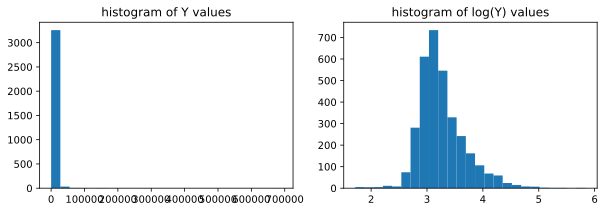

In [6]:
# map targets to log-space
trainY = log10(trainYo)
testY  = log10(testYo)

plt.figure(figsize=(10,3))
plt.subplot(1,2,1)
plt.hist(trainYo, 25);
plt.title('histogram of Y values')
plt.subplot(1,2,2)
plt.hist(trainY, 25);
plt.title("histogram of log(Y) values");

## 2. Prediction with Linear Regression

First we will look at predicting the number of shares using simple linear regression models.  Use the training data to fit a linear model using Ordinary Least Squares and Ridge Regression.  Use cross-validation on the training set to select the optimal $\alpha$ parameter for ridge regression.

In [7]:
### INSERT YOUR CODE HERE
## HINT:
# 1. Ordinary Least Squares: linear_model.LinearRegression()
# 2. Ridge Regression: linear_model.Ridge(alphas= )
# 3. Rigge Regression with Cross-validation: linear_model.RidgeCV(alphas= )

# --- Ordinary Least Squares ---
ols = linear_model.LinearRegression()
ols.fit(trainXn, trainY)

# --- Ridge Regression (with cross-validation) ---
# the next cell sweeps alpha and fits `rr` = RidgeCV(alphas, cv=5) on the training set

LinearRegression()

best alpha:  385.6620421163472
train error:  0.28859917591560874
test error :  0.2854267347255127


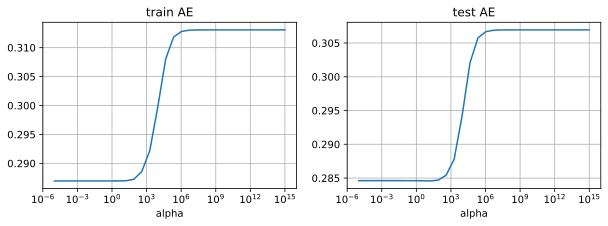

In [8]:
alphas = logspace(-5,15,30)

trainAEs = empty(len(alphas))
testAEs  = empty(len(alphas))
for i,a in enumerate(alphas):
    rr = linear_model.Ridge(alpha=a)
    rr.fit(trainXn, trainY)

    trainAEs[i] = metrics.mean_absolute_error(trainY, rr.predict(trainXn))
    testAEs[i]  = metrics.mean_absolute_error(testY, rr.predict(testXn))

plt.figure(figsize=(10,3))
plt.subplot(1,2,1)
plt.semilogx(alphas, trainAEs)
plt.xlabel('alpha')
plt.title('train AE')
plt.grid(True)
plt.subplot(1,2,2)
plt.semilogx(alphas, testAEs)
plt.xlabel('alpha')
plt.title('test AE')
plt.grid(True)

rr = linear_model.RidgeCV(alphas=alphas, cv=5)
rr.fit(trainXn, trainY)

print("best alpha: ", rr.alpha_)

trainAE = metrics.mean_absolute_error(trainY, rr.predict(trainXn))
testAE  = metrics.mean_absolute_error(testY,  rr.predict(testXn))

print("train error: ", trainAE)
print("test error : ", testAE)

Compare the two models using the _average absolute error_ (AE) between the predictions and the true values.  Below is  code that will calculate AE for the training and test sets.

In [9]:
# ols is the linear regression model
trainAE = metrics.mean_absolute_error(trainY, ols.predict(trainXn))
testAE  = metrics.mean_absolute_error(testY, ols.predict(testXn))
print("OLS: train error =", trainAE)
print("OLS: test error =", testAE)

OLS: train error = 0.28687000921804473
OLS: test error = 187.38235106719708


In [10]:
# rr is the ridge regression model
trainAE = metrics.mean_absolute_error(trainY, rr.predict(trainXn))
testAE  = metrics.mean_absolute_error(testY, rr.predict(testXn))
print("RR: train error =", trainAE)
print("RR: test error =", testAE)

RR: train error = 0.28859917591560874
RR: test error = 0.2854267347255127


Which model has better prediction ability on the test set? Why?

**Ridge regression is much better.** On the test set Ridge obtains AE $\approx 0.285$, while OLS explodes to AE $\approx 187$ — even though their **training** errors are almost the same (OLS 0.287 is even slightly lower than Ridge 0.289, since OLS directly minimizes the unregularized least-squares loss).

**Why:** many features are strongly correlated / redundant, e.g. `n_unique_tokens`, `n_non_stop_words`, `n_non_stop_unique_tokens`, `rate_positive_words` + `rate_negative_words` (sum to 1), and the one-hot channel / weekday dummies. With such collinearity the OLS problem is ill-conditioned: the learned weights become huge with opposite signs that almost cancel on the training data, but small differences in the test features get amplified into wild predictions (overfitting / high variance).

Ridge's $L_2$ penalty ($\alpha \approx 386$ selected by 5-fold CV) shrinks the weights towards zero. This adds a small amount of bias but greatly reduces the variance of the model, so it generalizes far better to the test set.

## 3. Which features are important?
Next we will investigate which features are the most important for the prediction.  Use LASSO with cross-validation to learn the model, and print the training and testing error.

In [11]:
### INSERT YOUR CODE HERE
## HINT
# 1. LASSO with Cross-validation: linear_model.LassoCV()

# LASSO with 5-fold cross-validation over the same alpha grid
las = linear_model.LassoCV(alphas=alphas, cv=5, max_iter=10000)
las.fit(trainXn, trainY)

print("best alpha: ", las.alpha_)
print("non-zero coefficients: {} / {}".format(sum(abs(las.coef_)>0), len(las.coef_)))

trainAE = metrics.mean_absolute_error(trainY, las.predict(trainXn))
testAE  = metrics.mean_absolute_error(testY, las.predict(testXn))
print("LASSO: train error =", trainAE)
print("LASSO: test error  =", testAE)

best alpha:  0.005736152510448681
non-zero coefficients: 35 / 58
LASSO: train error = 0.28966720935858153
LASSO: test error  = 0.28546981599559307


Examine the LASSO coefficients by sorting them in descending order.

In [12]:
# sort coefficients from smallest to largest, then reverse it
inds = argsort(abs(las.coef_))[::-1]
# print out
print("weight : feature description")
for i in inds:
    print("{: .3f} : {}".format(las.coef_[i], featnames[i]))

weight : feature description
 0.080 : kw_avg_avg
-0.043 : LDA_02
-0.033 : data_channel_is_entertainment
-0.026 : average_token_length
-0.026 : kw_max_avg
 0.024 : num_hrefs
 0.022 : kw_min_min
 0.022 : is_weekend
 0.022 : global_subjectivity
 0.019 : data_channel_is_socmed
 0.018 : self_reference_avg_sharess
-0.018 : data_channel_is_bus
 0.017 : n_tokens_content
-0.016 : kw_avg_min
 0.013 : LDA_00
 0.011 : title_sentiment_polarity
-0.009 : data_channel_is_lifestyle
-0.009 : max_positive_polarity
 0.008 : weekday_is_sunday
-0.008 : avg_negative_polarity
-0.007 : LDA_01
 0.006 : num_keywords
-0.005 : kw_min_max
 0.005 : n_tokens_title
-0.004 : weekday_is_friday
 0.004 : weekday_is_monday
 0.003 : self_reference_max_shares
 0.003 : LDA_03
-0.003 : weekday_is_tuesday
 0.002 : data_channel_is_tech
 0.002 : num_imgs
-0.001 : kw_avg_max
-0.001 : min_positive_polarity
-0.001 : rate_positive_words
-0.000 : num_self_hrefs
 0.000 : num_videos
-0.000 : avg_positive_polarity
-0.000 : min_negative_p

_Which features are most important for predicting the number of shares?  For these features, which feature values (low or high values) will yield a higher number of shares?_

The most important features (sorted by absolute LASSO weight) and their effects:

| feature | weight | high or low value → more shares? |
|---|---|---|
| `kw_avg_avg` | +0.080 | **HIGH** — articles about already-popular keywords are shared more (by far the strongest predictor) |
| `LDA_02` | −0.043 | **LOW** — articles strongly about LDA topic 2 are shared less |
| `data_channel_is_entertainment` | −0.033 | **LOW** (0) — entertainment articles get fewer shares |
| `average_token_length` | −0.026 | **LOW** — articles with shorter/simpler words are shared more |
| `kw_max_avg` | −0.026 | LOW |
| `num_hrefs` | +0.024 | **HIGH** — more hyperlinks → more shares |
| `kw_min_min` | +0.022 | HIGH |
| `is_weekend` | +0.022 | **HIGH** (1) — articles published at the weekend get more shares |
| `global_subjectivity` | +0.022 | **HIGH** — more subjective/opinionated articles spread better |
| `data_channel_is_socmed` | +0.019 | HIGH (1) — social-media topic articles get more shares |
| `self_reference_avg_sharess` | +0.018 | HIGH — referencing own popular articles helps |
| `data_channel_is_bus` | −0.018 | LOW (0) — business articles get fewer shares |
| `n_tokens_content` | +0.017 | HIGH — longer articles are shared slightly more |

In short: **high values** of `kw_avg_avg`, `kw_min_min`, `num_hrefs`, `global_subjectivity`, `self_reference_avg_sharess`, weekend publishing and social-media channel yield **more** shares; entertainment/business channels, topic `LDA_02`, long average words (`average_token_length`) and high `kw_max_avg` yield **fewer** shares. The keyword-popularity features (`kw_*`) dominate the prediction, which agrees with the reference paper's findings.

## 3. Kernel Methods and Supprot Vector Regression
Next, let us try some non-linear regression model such as[ kernel ridge regression](https://scikit-learn.org/stable/modules/kernel_ridge.html), [random forest regression](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)(Optional), [support vector regression](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html) to improve the prediction accuracy in Tutorial 3, and using cross-validation on the training set to select the parameters.

In [13]:
### INSERT YOUR CODE HERE
##Hint:
## 1. Kernel Ridge Regression:  kernel_ridge.KernelRidge(kernel='rbf'/'poly')
## 2. Random Forest Regression: ensemble.RandomForestRegressor(random_state= , n_estimators= )
## 3. Support Vector Regression: svm.SVR(kernel='poly')
## 4. Avoid using large values of C with SVR.

# dictionary to collect all models and their errors (a 'las-poly' model is added later)
clfs = {}
trainAE = {}
testAE  = {}

def evaluate(name, clf):
    """record train/test AE of a fitted model"""
    clfs[name] = clf
    trainAE[name] = metrics.mean_absolute_error(trainY, clf.predict(trainXn))
    testAE[name]  = metrics.mean_absolute_error(testY,  clf.predict(testXn))
    print("{:>10s}: train error = {:.4f}, test error = {:.4f}".format(
        name, trainAE[name], testAE[name]))

# 1) Kernel Ridge Regression with RBF kernel (select alpha & gamma by CV)
paramgrid = {'alpha': logspace(-3, 3, 7), 'gamma': logspace(-3, 2, 6)}
krr = model_selection.GridSearchCV(kernel_ridge.KernelRidge(kernel='rbf'),
                                   paramgrid, cv=5, n_jobs=-1)
krr.fit(trainXn, trainY)
print("best params:", krr.best_params_)
evaluate('krr-rbf', krr)

# 2) Random Forest Regression (optional)
paramgrid = {'n_estimators': [100, 300], 'max_depth': [10, 30, None]}
rf = model_selection.GridSearchCV(
    ensemble.RandomForestRegressor(random_state=4487, n_jobs=-1),
    paramgrid, cv=5)
rf.fit(trainXn, trainY)
print("best params:", rf.best_params_)
evaluate('rf', rf)

# 3) Support Vector Regression with polynomial kernel (use small C!)
paramgrid = {'C': logspace(-2, 1, 4), 'degree': [2, 3], 'epsilon': [0.05, 0.1]}
svrp = model_selection.GridSearchCV(svm.SVR(kernel='poly'), paramgrid,
                                    cv=5, n_jobs=-1)
svrp.fit(trainXn, trainY)
print("best params:", svrp.best_params_)
evaluate('svr-poly', svrp)

# 4) Support Vector Regression with RBF kernel
paramgrid = {'C': logspace(-2, 1, 4), 'gamma': logspace(-3, 1, 5), 'epsilon': [0.05, 0.1]}
svrr = model_selection.GridSearchCV(svm.SVR(kernel='rbf'), paramgrid,
                                    cv=5, n_jobs=-1)
svrr.fit(trainXn, trainY)
print("best params:", svrr.best_params_)
evaluate('svr-rbf', svrr)

# summary of all methods tried in this section
print("\n=== summary (train AE / test AE) ===")
for name in clfs:
    print("{:>10s}: {:.4f} / {:.4f}".format(name, trainAE[name], testAE[name]))

best params: {'alpha': 0.1, 'gamma': 0.001}


   krr-rbf: train error = 0.2731, test error = 0.2812


best params: {'max_depth': None, 'n_estimators': 300}


        rf: train error = 0.1085, test error = 0.2846


best params: {'C': 0.1, 'degree': 2, 'epsilon': 0.1}


  svr-poly: train error = 0.2610, test error = 0.2807


best params: {'C': 10.0, 'epsilon': 0.1, 'gamma': 0.001}


   svr-rbf: train error = 0.2558, test error = 0.2720

=== summary (train AE / test AE) ===
   krr-rbf: 0.2731 / 0.2812
        rf: 0.1085 / 0.2846
  svr-poly: 0.2610 / 0.2807
   svr-rbf: 0.2558 / 0.2720


In [14]:
# LASSO - poly features
polyfeats = preprocessing.PolynomialFeatures(degree=2)
trainXnf  = polyfeats.fit_transform(trainXn)
testXnf   = polyfeats.transform(testXn)

myname = 'las-poly'
clfs[myname] = linear_model.LassoCV(max_iter=2000)
clfs[myname].fit(trainXnf, trainY)
trainAE[myname] = metrics.mean_absolute_error(trainY, clfs[myname].predict(trainXnf))
testAE[myname]  = metrics.mean_absolute_error(testY, clfs[myname].predict(testXnf))

print("train error:", trainAE[myname])
print("test error :", testAE[myname])

C:\Users\admin\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_coordinate_descent.py:614: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.12805114206491908, tolerance: 0.044689521556202184
  model = cd_fast.enet_coordinate_descent_gram(


C:\Users\admin\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_coordinate_descent.py:614: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.5395722814628243, tolerance: 0.044689521556202184
  model = cd_fast.enet_coordinate_descent_gram(


C:\Users\admin\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_coordinate_descent.py:614: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.4431197919547003, tolerance: 0.044689521556202184
  model = cd_fast.enet_coordinate_descent_gram(


C:\Users\admin\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_coordinate_descent.py:614: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.45375685391979914, tolerance: 0.044689521556202184
  model = cd_fast.enet_coordinate_descent_gram(


C:\Users\admin\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_coordinate_descent.py:614: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.48093240293360395, tolerance: 0.044689521556202184
  model = cd_fast.enet_coordinate_descent_gram(


...

C:\Users\admin\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_coordinate_descent.py:614: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 1.508844304080867, tolerance: 0.04589222750537921
  model = cd_fast.enet_coordinate_descent_gram(


C:\Users\admin\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_coordinate_descent.py:614: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 2.5254717457197557, tolerance: 0.04589222750537921
  model = cd_fast.enet_coordinate_descent_gram(


C:\Users\admin\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_coordinate_descent.py:614: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 4.25276458334676, tolerance: 0.04589222750537921
  model = cd_fast.enet_coordinate_descent_gram(


C:\Users\admin\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_coordinate_descent.py:614: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 2.6305174946186582, tolerance: 0.04589222750537921
  model = cd_fast.enet_coordinate_descent_gram(


train error: 0.28285857893751243
test error : 0.2849816311879687


In [15]:
# sort coefficients from smallest to largest, then reverse it
inds = argsort(abs(clfs['las-poly'].coef_))[::-1]
print(len(polyfeats.powers_))
# print out
print("weight : feature description")
for i in inds:
    if abs(clfs['las-poly'].coef_[i])>1e-3:
        # get active features and powers
        pows = where(polyfeats.powers_[i])[0]
        fstr = ""
        for p in pows:
            fstr += featnames[p] + "(" + str(polyfeats.powers_[i][p]) + ") "
        print("{: .3f} : {}".format(clfs['las-poly'].coef_[i], fstr))

1770
weight : feature description
 0.089 : kw_avg_avg(1) 
 0.021 : kw_min_avg(2) 
-0.015 : data_channel_is_entertainment(2) 
-0.011 : LDA_02(2) 
 0.010 : global_subjectivity(1) 
 0.010 : self_reference_avg_sharess(1) 
 0.009 : kw_min_min(2) 
-0.009 : data_channel_is_world(1) LDA_02(1) 
-0.008 : weekday_is_monday(1) title_sentiment_polarity(1) 
 0.008 : weekday_is_sunday(2) 
 0.008 : data_channel_is_socmed(1) LDA_00(1) 


-0.008 : data_channel_is_lifestyle(1) max_positive_polarity(1) 
 0.008 : weekday_is_thursday(1) title_sentiment_polarity(1) 
-0.008 : data_channel_is_world(1) rate_negative_words(1) 
 0.008 : kw_max_avg(1) LDA_00(1) 
-0.007 : n_tokens_content(1) num_imgs(1) 
 0.007 : n_tokens_content(2) 
 0.007 : num_videos(1) data_channel_is_bus(1) 
 0.007 : kw_avg_avg(1) LDA_00(1) 
 0.007 : n_unique_tokens(1) rate_negative_words(1) 
-0.006 : n_tokens_title(1) n_tokens_content(1) 
 0.006 : data_channel_is_tech(2) 
 0.006 : num_keywords(1) kw_avg_max(1) 
-0.006 : kw_max_max(1) title_sentiment_polarity(1) 


 0.006 : n_tokens_content(1) num_hrefs(1) 
 0.005 : LDA_00(2) 
-0.005 : n_tokens_title(1) n_non_stop_words(1) 
-0.005 : weekday_is_monday(1) global_rate_negative_words(1) 
 0.004 : weekday_is_friday(1) max_positive_polarity(1) 
-0.004 : num_imgs(1) data_channel_is_socmed(1) 
 0.004 : title_sentiment_polarity(1) abs_title_sentiment_polarity(1) 
 0.004 : kw_min_avg(1) weekday_is_monday(1) 
 0.004 : data_channel_is_socmed(2) 
 0.004 : weekday_is_saturday(2) 
 0.004 : LDA_00(1) global_rate_positive_words(1) 
 0.004 : num_hrefs(2) 
-0.004 : kw_avg_max(1) kw_min_avg(1) 
-0.004 : num_keywords(1) data_channel_is_tech(1) 


-0.004 : data_channel_is_lifestyle(1) avg_positive_polarity(1) 
-0.003 : num_hrefs(1) data_channel_is_socmed(1) 
 0.003 : LDA_03(1) rate_negative_words(1) 
 0.003 : n_tokens_title(1) LDA_03(1) 
-0.003 : kw_max_avg(1) kw_avg_avg(1) 
-0.003 : kw_min_avg(1) self_reference_max_shares(1) 
-0.003 : LDA_03(1) global_rate_positive_words(1) 
 0.003 : global_sentiment_polarity(1) min_positive_polarity(1) 
 0.002 : n_non_stop_words(1) weekday_is_wednesday(1) 
-0.002 : min_negative_polarity(2) 
 0.002 : global_rate_negative_words(1) title_sentiment_polarity(1) 
-0.002 : rate_negative_words(1) abs_title_subjectivity(1) 
 0.002 : num_imgs(1) min_positive_polarity(1) 
-0.002 : kw_max_avg(2) 


 0.002 : weekday_is_monday(2) 
-0.002 : data_channel_is_lifestyle(2) 
-0.002 : data_channel_is_bus(2) 
-0.002 : num_keywords(2) 
-0.002 : num_self_hrefs(2) 
-0.002 : data_channel_is_lifestyle(1) weekday_is_monday(1) 
 0.001 : num_imgs(2) 
-0.001 : weekday_is_thursday(1) global_rate_positive_words(1) 
-0.001 : kw_avg_avg(1) is_weekend(1) 
 0.001 : data_channel_is_bus(1) global_rate_negative_words(1) 
 0.001 : self_reference_min_shares(1) LDA_04(1) 
-0.001 : kw_max_max(1) abs_title_sentiment_polarity(1) 


 0.001 : num_hrefs(1) 
-0.001 : kw_min_avg(1) kw_max_avg(1) 
 0.001 : kw_max_avg(1) self_reference_max_shares(1) 
 0.001 : avg_positive_polarity(1) title_subjectivity(1) 
 0.001 : kw_max_max(2) 
 0.001 : self_reference_max_shares(1) abs_title_sentiment_polarity(1) 
-0.001 : global_rate_negative_words(2) 


_Which regression method performs the best? Why do you think so?_

**SVR with the RBF kernel performs the best** — test AE $\approx 0.272$, the lowest of all methods tried:

| method | train AE | test AE |
|---|---|---|
| ridge / LASSO (linear) | ~0.29 | ~0.285 |
| LASSO + poly features | 0.283 | 0.285 |
| random forest | 0.109 | 0.285 |
| krr-rbf | 0.273 | 0.281 |
| svr-poly | 0.261 | 0.281 |
| **svr-rbf** | 0.256 | **0.272** |

Why I think it wins:

- The RBF kernel captures **non-linear feature–target relationships** that the linear models cannot express. Cross-validation selected a small $\gamma$ (0.001), so the kernel function is still very smooth — the model bends where needed but does not chase individual noise points.
- SVR's **$\epsilon$-insensitive loss** ($\epsilon = 0.1$) ignores errors smaller than $\epsilon$. The number of shares is very noisy, so being "robust to small errors" instead of penalizing every residual quadratically reduces the influence of noise and outliers, and only the support vectors matter for prediction.
- The regularization parameter $C$ (selected as 10, not too large) explicitly trades off training fit vs. model flatness, keeping the variance low.

For comparison: the **random forest** overfits badly (train AE 0.109 vs test AE 0.285 — unlimited depth memorizes the training set), and **LASSO with polynomial features** gives essentially no improvement over linear LASSO (0.285), suggesting there is little useful high-order interaction structure in this data — most of the gain comes from smooth non-linearity, which is exactly what the RBF SVR provides.